# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

### Setup
Installs dependencies, defines helpers and (for Notebooks 3-7) loads the shared `config.json` written by Notebook 2. Run this cell first.

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ---- Environment setup (Google Colab / local Jupyter) ----
import os, sys, glob, zipfile, json, random, warnings
warnings.filterwarnings("ignore")

USE_DRIVE = False   # set True on Colab to keep artifacts (chroma_db, adapters, csv) across runtime resets
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/RAG/Dataset/Output/"
    os.makedirs(WORKDIR, exist_ok=True)
    os.chdir(WORKDIR)
print("Working directory:", os.getcwd())

%pip install -q transformers accelerate bitsandbytes peft datasets pandas numpy matplotlib

# ---- Load the single-source-of-truth configuration written by Notebook 2 ----
if not os.path.exists("/content/drive/MyDrive/RAG/Dataset/Output/config.json"):
    raise FileNotFoundError("config.json not found - run Notebook 2 (Data Preparation) first.")
cfg = json.load(open("/content/drive/MyDrive/RAG/Dataset/Output/config.json"))
MODEL_ID       = cfg["MODEL_ID"]
EMBED_MODEL    = cfg["EMBED_MODEL"]
SEED           = cfg["SEED"]
BASELINE_SYSTEM = cfg["BASELINE_SYSTEM"]
RAG_SYSTEM     = cfg["RAG_SYSTEM"]          # contains the {context} placeholder
ROUTER_SYSTEM  = cfg["ROUTER_SYSTEM"]
MAX_NEW_TOKENS = cfg["MAX_NEW_TOKENS"]
CHROMA_DIR     = cfg["CHROMA_DIR"]
COLLECTION     = cfg["COLLECTION"]
random.seed(SEED)
print("MODEL_ID:", MODEL_ID, "| EMBED_MODEL:", EMBED_MODEL, "| SEED:", SEED)

Working directory: /content
MODEL_ID: Qwen/Qwen2.5-1.5B-Instruct | EMBED_MODEL: sentence-transformers/all-MiniLM-L6-v2 | SEED: 42


## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [3]:
import time, math, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# ---- reproducibility ---------------------------------------------------------------------------------
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
HAS_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda" if HAS_CUDA else "cpu")
COMPUTE_DTYPE = torch.bfloat16 if (HAS_CUDA and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
print("Device:", DEVICE, "| compute dtype:", COMPUTE_DTYPE)
if not HAS_CUDA: print("WARNING: no GPU - training on CPU will be extremely slow. Enable a T4 GPU runtime.")

# ---- tokenised data from Notebook 2 (re-apply set_format after load_from_disk) -----------------------------------
ds_train = load_from_disk("/content/drive/MyDrive/RAG/Dataset/Output/tokenized_train"); ds_valid = load_from_disk("/content/drive/MyDrive/RAG/Dataset/Output/tokenized_valid")
TORCH_COLS = ["input_ids", "attention_mask", "labels"]
ds_train.set_format("torch", columns=TORCH_COLS); ds_valid.set_format("torch", columns=TORCH_COLS)
print("train:", len(ds_train), "| valid:", len(ds_valid), "| sequence length:", ds_train[0]["input_ids"].shape[0])

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
sup = ds_train[0]["labels"][ds_train[0]["labels"] != -100]
print("Supervised tokens of example 0 ->", repr(tokenizer.decode(sup)))

# ---- QLoRA: 4-bit NF4 frozen base model + trainable LoRA adapters ---------------------------------------------
QUANT = HAS_CUDA
if QUANT:
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_config, device_map={"": 0})
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=False)
else:
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32)
base.config.use_cache = False

lora_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                         target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
peft_model = get_peft_model(base, lora_config)
peft_model.print_trainable_parameters()
n_train = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in peft_model.parameters())
print(f"Trainable parameters: {n_train:,} / {n_total:,} = {n_train / n_total * 100:.2f}%")
assert n_train / n_total < 0.05, "LoRA should update only a tiny fraction of the weights"

Device: cuda | compute dtype: torch.float16
train: 3196 | valid: 400 | sequence length: 128


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410
Trainable parameters: 2,179,072 / 890,795,520 = 0.24%


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [5]:
from torch.utils.data import DataLoader

LR, BATCH_SIZE, EVAL_BATCH_SIZE = 2e-4, 4, 8
MAX_STEPS, WARMUP_STEPS = 400, 20          # 400 steps x 4 = 1,600 examples = 0.5 epoch of the 3,200-row train split
VAL_EVERY, PATIENCE = 20, 3                # validate every 20 steps; stop if val loss fails to improve 3 checks in a row
MAX_GRAD_NORM, WEIGHT_DECAY = 1.0, 0.0

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g, drop_last=True)
valid_loader = DataLoader(ds_valid, batch_size=EVAL_BATCH_SIZE, shuffle=False)

optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=WARMUP_STEPS, num_training_steps=MAX_STEPS)
USE_FP16 = HAS_CUDA and COMPUTE_DTYPE == torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)           # loss scaling needed only for fp16 (T4)
AMP_DTYPE = COMPUTE_DTYPE if HAS_CUDA else torch.float32

BEST_DIR, FINAL_DIR = "./intent_lora_best", "./intent_lora"
print(f"AdamW lr={LR} | batch={BATCH_SIZE} | max_steps={MAX_STEPS} (~{MAX_STEPS*BATCH_SIZE/len(ds_train):.2f} epoch) | warmup={WARMUP_STEPS}")
print(f"Validation every {VAL_EVERY} steps | early-stopping patience={PATIENCE} checks | quantisation: {'4-bit NF4 (QLoRA), compute '+str(COMPUTE_DTYPE) if QUANT else 'none (CPU)'} | mixed precision fp16={USE_FP16}")
print("Train batches per epoch:", len(train_loader), "| valid batches:", len(valid_loader))

AdamW lr=0.0002 | batch=4 | max_steps=400 (~0.50 epoch) | warmup=20
Validation every 20 steps | early-stopping patience=3 checks | quantisation: 4-bit NF4 (QLoRA), compute torch.float16 | mixed precision fp16=True
Train batches per epoch: 799 | valid batches: 50


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [6]:
def infinite(loader):
    while True:
        for b in loader:
            yield b

@torch.no_grad()
def run_validation():
    peft_model.eval()
    tot, n = 0.0, 0
    for b in valid_loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=HAS_CUDA):
            loss = peft_model(**b).loss
        tot += loss.item() * b["input_ids"].size(0); n += b["input_ids"].size(0)
    peft_model.train()
    return tot / n

peft_model.train()
batches = infinite(train_loader)
step_losses, log_rows, window = [], [], []
best_val, best_step, bad_checks, stopped_early = float("inf"), 0, 0, False
t0 = time.time()

for step in range(1, MAX_STEPS + 1):
    batch = {k: v.to(DEVICE) for k, v in next(batches).items()}
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=HAS_CUDA):
        loss = peft_model(**batch).loss
    if not torch.isfinite(loss):
        raise RuntimeError(f"non-finite loss at step {step}")
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_([p for p in peft_model.parameters() if p.requires_grad], MAX_GRAD_NORM)
    scaler.step(optimizer); scaler.update(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
    step_losses.append(loss.item()); window.append(loss.item())

    if step % VAL_EVERY == 0 or step == MAX_STEPS:
        val_loss, tr_loss = run_validation(), float(np.mean(window)); window = []
        log_rows.append({"step": step, "train_loss": tr_loss, "val_loss": val_loss, "lr": scheduler.get_last_lr()[0]})
        improved = val_loss < best_val - 1e-4
        if improved:
            best_val, best_step, bad_checks = val_loss, step, 0
            peft_model.save_pretrained(BEST_DIR)                 # best checkpoint by VALIDATION loss
        else:
            bad_checks += 1
        print(f"step {step:4d}/{MAX_STEPS} | train {tr_loss:.4f} | val {val_loss:.4f} | best {best_val:.4f}@{best_step} | "
              f"{'saved best' if improved else f'no improvement ({bad_checks}/{PATIENCE})'} | {(time.time()-t0)/60:.1f} min")
        if bad_checks >= PATIENCE:
            stopped_early = True
            print(f"EARLY STOPPING at step {step}: validation loss did not improve for {PATIENCE} consecutive checks.")
            break

steps_run = step
training_log = pd.DataFrame(log_rows)
print(f"\nTraining finished: {steps_run} steps in {(time.time()-t0)/60:.1f} min | best val loss {best_val:.4f} at step {best_step} | early stop: {stopped_early}")

step   20/400 | train 0.9013 | val 0.5434 | best 0.5434@20 | saved best | 0.4 min
step   40/400 | train 0.4254 | val 0.2909 | best 0.2909@40 | saved best | 0.7 min
step   60/400 | train 0.1881 | val 0.1606 | best 0.1606@60 | saved best | 1.0 min
step   80/400 | train 0.1108 | val 0.1076 | best 0.1076@80 | saved best | 1.4 min
step  100/400 | train 0.0731 | val 0.0594 | best 0.0594@100 | saved best | 1.8 min
step  120/400 | train 0.0552 | val 0.0464 | best 0.0464@120 | saved best | 2.2 min
step  140/400 | train 0.0434 | val 0.0884 | best 0.0464@120 | no improvement (1/3) | 2.5 min
step  160/400 | train 0.0443 | val 0.0385 | best 0.0385@160 | saved best | 2.9 min
step  180/400 | train 0.0268 | val 0.0289 | best 0.0289@180 | saved best | 3.3 min
step  200/400 | train 0.0258 | val 0.0220 | best 0.0220@200 | saved best | 3.6 min
step  220/400 | train 0.0350 | val 0.0172 | best 0.0172@220 | saved best | 4.0 min
step  240/400 | train 0.0249 | val 0.0126 | best 0.0126@240 | saved best | 4.4 mi

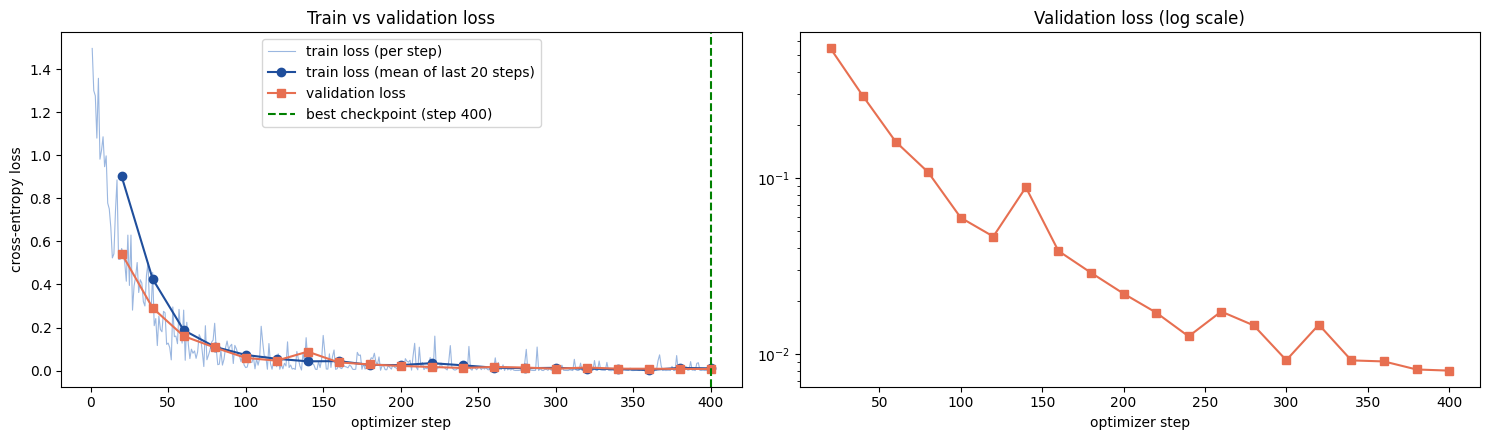

Train loss 0.901 -> 0.011 | val loss 0.543 -> 0.008 | gap (val-train) -0.003
Interpretation: both curves fall - gradient descent is teaching the JSON-extraction task.


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(range(1, len(step_losses) + 1), step_losses, color="#9bb7e0", lw=0.8, label="train loss (per step)")
ax[0].plot(training_log["step"], training_log["train_loss"], "o-", color="#1f4e9c", label=f"train loss (mean of last {VAL_EVERY} steps)")
ax[0].plot(training_log["step"], training_log["val_loss"], "s-", color="#e76f51", label="validation loss")
ax[0].axvline(best_step, color="green", ls="--", label=f"best checkpoint (step {best_step})")
ax[0].set_xlabel("optimizer step"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Train vs validation loss"); ax[0].legend()
ax[1].plot(training_log["step"], training_log["val_loss"], "s-", color="#e76f51"); ax[1].set_yscale("log")
ax[1].set_title("Validation loss (log scale)"); ax[1].set_xlabel("optimizer step")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

first, last = training_log.iloc[0], training_log.iloc[-1]
gap = last["val_loss"] - last["train_loss"]
print(f"Train loss {first['train_loss']:.3f} -> {last['train_loss']:.3f} | val loss {first['val_loss']:.3f} -> {last['val_loss']:.3f} | gap (val-train) {gap:+.3f}")
if last["val_loss"] <= first["val_loss"] * 0.5:
    print("Interpretation: both curves fall - gradient descent is teaching the JSON-extraction task.")
if len(training_log) >= 3 and training_log["val_loss"].iloc[-1] > training_log["val_loss"].min() * 1.05 and training_log["train_loss"].iloc[-1] < training_log["train_loss"].iloc[-3]:
    print("Warning: val loss rising while train falls -> overfitting; the best (not last) checkpoint is used downstream.")

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [9]:
import transformers, peft, platform
# --- checkpoint workflow --------------------------------------------------------------------------------------
#  1. every validation check: if val loss improved -> peft_model.save_pretrained("./intent_lora_best")   (BEST by val loss)
#  2. after the last step                          -> peft_model.save_pretrained("./intent_lora")        (FINAL step)
#  Only the small LoRA adapter (a few MB) is saved; the frozen 4-bit base model is re-loaded from MODEL_ID.
peft_model.save_pretrained(FINAL_DIR)
for d in (BEST_DIR, FINAL_DIR):
    files = sorted(os.listdir(d)); print(f"{d}: {files}")
    assert "adapter_config.json" in files and any(f.startswith("adapter_model") for f in files), f"incomplete checkpoint in {d}"

# --- training log ---------------------------------------------------------------------------------------------
training_log[["step", "train_loss", "val_loss"]].to_csv("training_log.csv", index=False)

# --- reproducibility record -----------------------------------------------------------------------------------
repro = {
    "model_id": MODEL_ID, "seed": SEED, "quantisation": "4-bit NF4 + double-quant (QLoRA)" if QUANT else "none",
    "lora": {"r": lora_config.r, "alpha": lora_config.lora_alpha, "dropout": lora_config.lora_dropout, "target_modules": sorted(lora_config.target_modules)},
    "optimizer": "torch.optim.AdamW", "learning_rate": LR, "weight_decay": WEIGHT_DECAY, "scheduler": f"linear, warmup {WARMUP_STEPS}",
    "batch_size": BATCH_SIZE, "max_steps": MAX_STEPS, "steps_run": steps_run, "val_every": VAL_EVERY, "patience": PATIENCE,
    "early_stopped": stopped_early, "best_step": best_step, "best_val_loss": best_val, "max_length": cfg["MAX_LENGTH"],
    "train_rows": len(ds_train), "valid_rows": len(ds_valid), "trainable_params": n_train, "total_params": n_total,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__, "peft": peft.__version__, "python": platform.python_version()},
    "gpu": torch.cuda.get_device_name(0) if HAS_CUDA else "cpu",
}
json.dump(repro, open("reproducibility.json", "w"), indent=2)
print(json.dumps(repro, indent=2))
display(pd.read_csv("training_log.csv").tail())
print("Saved: ./intent_lora_best/ (used by Notebook 7), ./intent_lora/, training_log.csv, training_curves.png, reproducibility.json")

./intent_lora_best: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
./intent_lora: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
{
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "seed": 42,
  "quantisation": "4-bit NF4 + double-quant (QLoRA)",
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "target_modules": [
      "q_proj",
      "v_proj"
    ]
  },
  "optimizer": "torch.optim.AdamW",
  "learning_rate": 0.0002,
  "weight_decay": 0.0,
  "scheduler": "linear, warmup 20",
  "batch_size": 4,
  "max_steps": 400,
  "steps_run": 400,
  "val_every": 20,
  "patience": 3,
  "early_stopped": false,
  "best_step": 400,
  "best_val_loss": 0.008037791450042277,
  "max_length": 128,
  "train_rows": 3196,
  "valid_rows": 400,
  "trainable_params": 2179072,
  "total_params": 890795520,
  "versions": {
    "torch": "2.14.1+cu130",
    "transformers": "5.22.1",
    "peft": "0.21.2",
    "python": "3.13.16"
  },
  "gpu": "Tesla T4"
}


,step,train_loss,val_loss
15,320,0.009082,0.014662
16,340,0.007779,0.009187
17,360,0.003218,0.009062
18,380,0.012947,0.008159
19,400,0.010668,0.008038


Saved: ./intent_lora_best/ (used by Notebook 7), ./intent_lora/, training_log.csv, training_curves.png, reproducibility.json


In [11]:
import shutil
import os

destination_dir = "/content/drive/MyDrive/RAG/Dataset/Output/"
files_to_move = [
    "/content/training_log.csv",
    "/content/training_curves.png",
    "/content/reproducibility.json"
]

os.makedirs(destination_dir, exist_ok=True)

for file_path in files_to_move:
    if os.path.exists(file_path):
        dest_file_path = os.path.join(destination_dir, os.path.basename(file_path))
        if os.path.exists(dest_file_path):
            os.remove(dest_file_path)
        shutil.move(file_path, destination_dir)
        print(f"Moved {os.path.basename(file_path)} to Drive.")
    else:
        print(f"File not found: {file_path}")

Moved training_log.csv to Drive.
Moved training_curves.png to Drive.
Moved reproducibility.json to Drive.


In [10]:
import shutil

destination_dir = "/content/drive/MyDrive/RAG/Dataset/Output/"

# Move intent_lora folder
if os.path.exists("./intent_lora"):
    dest_lora = os.path.join(destination_dir, "intent_lora")
    if os.path.exists(dest_lora):
        shutil.rmtree(dest_lora)
    shutil.move("./intent_lora", destination_dir)
    print("Moved intent_lora to Drive.")

# Move intent_lora_best folder
if os.path.exists("./intent_lora_best"):
    dest_lora_best = os.path.join(destination_dir, "intent_lora_best")
    if os.path.exists(dest_lora_best):
        shutil.rmtree(dest_lora_best)
    shutil.move("./intent_lora_best", destination_dir)
    print("Moved intent_lora_best to Drive.")

Moved intent_lora to Drive.
Moved intent_lora_best to Drive.


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**